# Prueba de camara DroidCam + ArUco

Cuadernillo para probar la conexion de la camara del celular Xiaomi Redmi Note 13 5G usando DroidCam por USB.

Objetivo:
1. Verificar que OpenCV puede abrir la camara.
2. Detectar los 4 marcadores ArUco del tablero.
3. Capturar una imagen estable.
4. Enderezar el tablero.
5. Segmentar las 64 casillas y guardarlas con notacion de ajedrez.


## 1. Instalacion opcional

Ejecuta esta celda solo si falta alguna libreria. Para ArUco necesitas `opencv-contrib-python`.

In [ ]:
# Ejecuta solo si hace falta:
# !pip install opencv-contrib-python numpy matplotlib


## 2. Imports y configuracion

DroidCam puede funcionar de dos formas distintas:

- **Python directo por IP**: cierra DroidCam Client en la PC y deja abierta solo la app DroidCam del celular. Python lee `http://10.77.209.23:4747/video` o `http://192.168.1.6:4747/video`.
- **Python por camara virtual**: deja DroidCam Client abierto, selecciona `Redmi` o `2312DRA50G [USB]`, activa el video y Python lee el indice de la camara virtual. En este modo OpenCV no lee el celular directo, lee la webcam virtual creada por DroidCam.

Si el cliente DroidCam esta mostrando video, pero Python no ve la IP, prueba cerrar DroidCam Client y ejecutar la prueba por IP. Si quieres usar el cliente abierto, prueba indices con varios backends.


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
import urllib.request
from IPython.display import clear_output, display

ROOT = Path.cwd()
OUTPUT_DIR = ROOT / "Dataset" / "prueba_camara"
CASILLAS_DIR = OUTPUT_DIR / "casillas_ajedrez"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CASILLAS_DIR.mkdir(parents=True, exist_ok=True)

# OPCION A: indice local. Sirve si DroidCam aparece como webcam virtual en Windows.
CAMERA_INDEX = 0

# OPCION B: IP DroidCam. Device IP suele ser para USB; WiFi IP para conexion por red.
DROIDCAM_DEVICE_IP = "192.168.1.2"
DROIDCAM_WIFI_IP = "10.204.120.246"
DROIDCAM_PORT = 4747

# Fuente recomendada para probar Python directo por IP.
CAMERA_SOURCE = f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video"

# Pruebas comunes para DroidCam. Algunas versiones responden a /video y otras a /mjpegfeed.
DROIDCAM_URLS = [
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video?640x480",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video?640x480",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/",
]

# Backends locales para buscar webcam virtual de DroidCam.
CAMERA_BACKENDS = [
    (cv2.CAP_DSHOW, "CAP_DSHOW"),
    (cv2.CAP_MSMF, "CAP_MSMF"),
    (cv2.CAP_ANY, "CAP_ANY"),
]

CAMERA_WIDTH = 1280
CAMERA_HEIGHT = 720

# Debe coincidir con el tipo de marcadores que imprimiste.
ARUCO_DICT = cv2.aruco.DICT_4X4_50

BOARD_SIZE = 800
CELL_MARGIN = 0.00

print("Salida:", OUTPUT_DIR)
print("OpenCV:", cv2.__version__)
print("Tiene modulo aruco:", hasattr(cv2, "aruco"))
print("Fuente actual:", CAMERA_SOURCE)


Salida: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_camara
OpenCV: 4.10.0
Tiene modulo aruco: True
Fuente actual: http://192.168.1.2:4747/video


## 3. Buscar fuentes de camara

Usa estas pruebas segun el modo:

- Si quieres leer por IP directa: cierra DroidCam Client en Windows y ejecuta `probar_urls_droidcam()`.
- Si quieres leer la camara virtual: deja DroidCam Client abierto mostrando video y ejecuta `probar_indices_camara(20)`.

No ejecutes ambas automaticamente si una se demora; corre primero la que corresponde a tu modo.


HTTP OK 200: http://192.168.1.2:4747/video | multipart/x-mixed-replace;boundary=--dcmjpeg
HTTP fallo: http://192.168.1.2:4747/mjpegfeed | HTTPError: HTTP Error 404: Not Found
HTTP OK 200: http://192.168.1.2:4747/video?640x480 | text/html; charset=UTF-8
HTTP OK 200: http://192.168.1.2:4747/ | text/html; charset=UTF-8
HTTP fallo: http://10.204.120.246:4747/video | URLError: <urlopen error timed out>
HTTP fallo: http://10.204.120.246:4747/mjpegfeed | URLError: <urlopen error timed out>
HTTP fallo: http://10.204.120.246:4747/video?640x480 | URLError: <urlopen error timed out>
HTTP fallo: http://10.204.120.246:4747/ | URLError: <urlopen error timed out>
Probando URL con OpenCV: http://192.168.1.2:4747/video
  OK - resolucion leida 1280x720


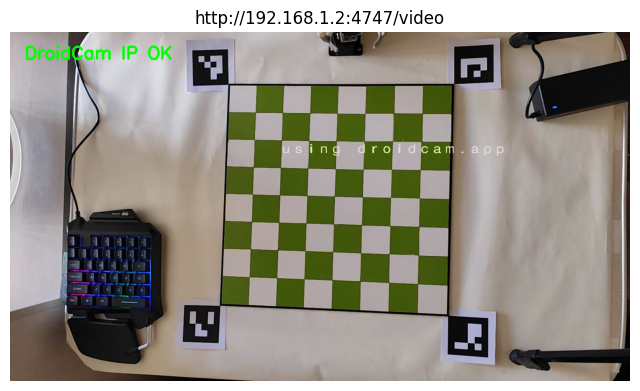

Probando URL con OpenCV: http://192.168.1.2:4747/mjpegfeed
  Sin video
Probando URL con OpenCV: http://192.168.1.2:4747/video?640x480
  OK - resolucion leida 640x480


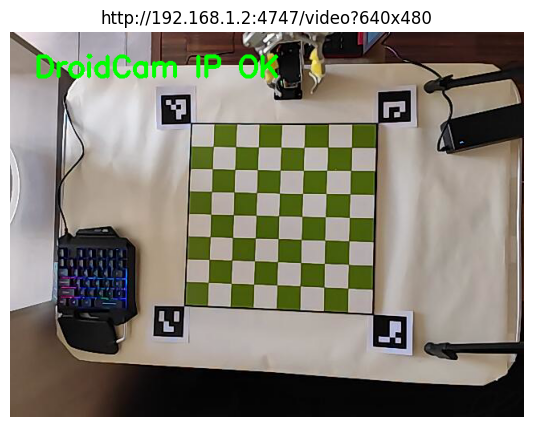

Probando URL con OpenCV: http://192.168.1.2:4747/
  Sin video
Probando URL con OpenCV: http://10.204.120.246:4747/video
  Sin video
Probando URL con OpenCV: http://10.204.120.246:4747/mjpegfeed
  Sin video
Probando URL con OpenCV: http://10.204.120.246:4747/video?640x480
  Sin video
Probando URL con OpenCV: http://10.204.120.246:4747/
  Sin video
URLs disponibles: ['http://192.168.1.2:4747/video', 'http://192.168.1.2:4747/video?640x480']
CAMERA_SOURCE = http://192.168.1.2:4747/video


In [2]:
def mostrar_frame_notebook(frame_bgr, titulo="Frame", figsize=(8, 5)):
    """Muestra un frame BGR dentro del notebook sin usar cv2.imshow."""
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(frame_rgb)
    plt.title(titulo)
    plt.axis("off")
    plt.show()


def _abrir_video_capture(source, backend=None):
    """Abre una fuente OpenCV. Para int puede probar backends; para URL usa backend automatico."""
    if isinstance(source, int):
        if backend is None:
            cap = cv2.VideoCapture(source, cv2.CAP_DSHOW)
        else:
            cap = cv2.VideoCapture(source, backend)
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, CAMERA_WIDTH)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, CAMERA_HEIGHT)
    else:
        cap = cv2.VideoCapture(str(source))
    return cap


def leer_primer_frame(source, intentos=20, espera=0.08, backend=None):
    cap = _abrir_video_capture(source, backend=backend)
    frame = None

    try:
        for _ in range(intentos):
            ok, frame = cap.read()
            if ok and frame is not None:
                return True, frame
            time.sleep(espera)
    finally:
        cap.release()

    return False, None


def probar_http_basico(urls=DROIDCAM_URLS, timeout=2):
    """Verifica si la URL responde por HTTP antes de intentar VideoCapture."""
    resultados = []
    for url in urls:
        try:
            with urllib.request.urlopen(url, timeout=timeout) as resp:
                content_type = resp.headers.get("Content-Type", "")
                status = getattr(resp, "status", "OK")
                print(f"HTTP OK {status}: {url} | {content_type}")
                resultados.append((url, True, content_type))
        except Exception as exc:
            print(f"HTTP fallo: {url} | {type(exc).__name__}: {exc}")
            resultados.append((url, False, str(exc)))
    return resultados


def probar_indices_camara(max_index=20, mostrar=True):
    disponibles = []

    for backend, backend_name in CAMERA_BACKENDS:
        print(f"=== Backend {backend_name} ===")
        for idx in range(max_index + 1):
            ok, frame = leer_primer_frame(idx, intentos=12, espera=0.06, backend=backend)

            if ok:
                alto, ancho = frame.shape[:2]
                item = {"index": idx, "backend": backend, "backend_name": backend_name, "shape": (alto, ancho)}
                disponibles.append(item)
                print(f"Indice {idx} con {backend_name}: OK - {ancho}x{alto}")

                if mostrar:
                    frame_marcado = frame.copy()
                    cv2.putText(frame_marcado, f"idx {idx} {backend_name}", (30, 55), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
                    mostrar_frame_notebook(frame_marcado, titulo=f"Indice {idx} - {backend_name}")
            else:
                print(f"Indice {idx} con {backend_name}: sin video")

    print("Fuentes locales detectadas:", disponibles)
    return disponibles


def probar_urls_droidcam(urls=DROIDCAM_URLS, mostrar=True):
    disponibles = []

    for url in urls:
        print(f"Probando URL con OpenCV: {url}")
        ok, frame = leer_primer_frame(url, intentos=45, espera=0.1)

        if ok:
            disponibles.append(url)
            alto, ancho = frame.shape[:2]
            print(f"  OK - resolucion leida {ancho}x{alto}")

            if mostrar:
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, "DroidCam IP OK", (30, 55), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
                mostrar_frame_notebook(frame_marcado, titulo=url)
        else:
            print("  Sin video")

    print("URLs disponibles:", disponibles)
    return disponibles


def usar_fuente_local(item):
    """Configura CAMERA_SOURCE y CAMERA_BACKEND_ACTUAL desde un item devuelto por probar_indices_camara."""
    global CAMERA_SOURCE, CAMERA_BACKEND_ACTUAL
    CAMERA_SOURCE = int(item["index"])
    CAMERA_BACKEND_ACTUAL = item["backend"]
    print("CAMERA_SOURCE =", CAMERA_SOURCE)
    print("CAMERA_BACKEND_ACTUAL =", item["backend_name"])


def usar_fuente_ip(url):
    """Configura CAMERA_SOURCE desde una URL devuelta por probar_urls_droidcam."""
    global CAMERA_SOURCE, CAMERA_BACKEND_ACTUAL
    CAMERA_SOURCE = url
    CAMERA_BACKEND_ACTUAL = None
    print("CAMERA_SOURCE =", CAMERA_SOURCE)


CAMERA_BACKEND_ACTUAL = None

# MODO IP DIRECTA: cierra DroidCam Client en Windows y ejecuta estas dos lineas.
http_resultados = probar_http_basico()
urls_ok = probar_urls_droidcam()
if urls_ok: usar_fuente_ip(urls_ok[0])

# MODO CAMARA VIRTUAL: deja DroidCam Client abierto mostrando video y ejecuta estas lineas.
# locales_ok = probar_indices_camara(20)
# if locales_ok: usar_fuente_local(locales_ok[0])


## 4. Vista previa de DroidCam

Usa `CAMERA_SOURCE`. Por defecto apunta a `http://10.77.209.23:4747/video`. Si una prueba anterior te dio otra fuente, cambia `CAMERA_SOURCE` en la configuracion.


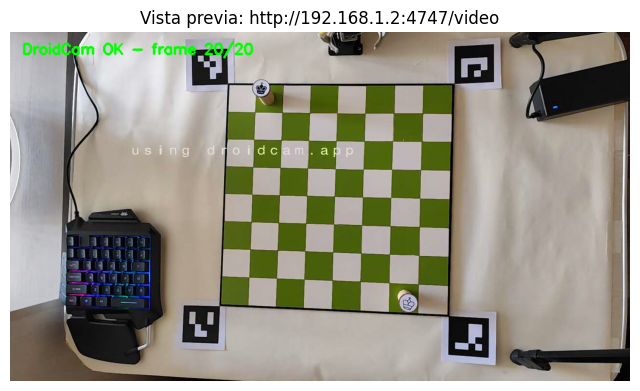

In [3]:
def abrir_camara(source=CAMERA_SOURCE):
    backend = CAMERA_BACKEND_ACTUAL if isinstance(source, int) else None
    cap = _abrir_video_capture(source, backend=backend)

    if not cap.isOpened():
        raise RuntimeError(
            f"No se pudo abrir la fuente de camara: {source}\n"
            "Si usas IP directa, cierra DroidCam Client y deja solo la app del celular. "
            "Si usas camara virtual, deja DroidCam Client abierto y usa el indice/backend detectado."
        )

    return cap


def capturar_frame_simple(source=CAMERA_SOURCE, warmup_frames=20):
    """Toma una sola imagen de la camara y la devuelve. No usa ventanas GUI."""
    cap = abrir_camara(source)
    frame = None

    try:
        for _ in range(warmup_frames):
            ok, frame = cap.read()
            if not ok:
                frame = None
            time.sleep(0.04)
    finally:
        cap.release()

    if frame is None:
        raise RuntimeError("No se pudo leer una imagen desde la camara.")

    return frame


def vista_previa_notebook(source=None, frames=20, intervalo=0.15):
    """Muestra algunos frames dentro del notebook. Sirve como vista previa sin cv2.imshow."""
    if source is None:
        source = CAMERA_SOURCE

    cap = abrir_camara(source)
    ultimo = None

    try:
        for i in range(frames):
            ok, frame = cap.read()
            if not ok or frame is None:
                print(f"Frame {i}: no disponible")
                time.sleep(intervalo)
                continue

            ultimo = frame.copy()
            frame_marcado = frame.copy()
            cv2.putText(frame_marcado, f"DroidCam OK - frame {i+1}/{frames}", (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 3)

            clear_output(wait=True)
            mostrar_frame_notebook(frame_marcado, titulo=f"Vista previa: {source}")
            time.sleep(intervalo)
    finally:
        cap.release()

    return ultimo


# Ejecuta esta linea cuando ya hayas configurado CAMERA_SOURCE:
frame_preview = vista_previa_notebook(frames=20)


## 5. Funciones ArUco

Basado en `Dataset/Deteccion_Aruco.ipynb`: detecta 4 marcadores, calcula las esquinas internas del tablero y ordena los puntos.

In [4]:
def ordenar_puntos(pts):
    pts = np.array(pts, dtype="float32")

    suma = pts.sum(axis=1)
    resta = np.diff(pts, axis=1)

    ordenados = np.zeros((4, 2), dtype="float32")
    ordenados[0] = pts[np.argmin(suma)]   # superior izquierda
    ordenados[2] = pts[np.argmax(suma)]   # inferior derecha
    ordenados[1] = pts[np.argmin(resta)]  # superior derecha
    ordenados[3] = pts[np.argmax(resta)]  # inferior izquierda

    return ordenados


def detectar_aruco(imagen_bgr):
    gray = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)

    aruco_dict = cv2.aruco.getPredefinedDictionary(ARUCO_DICT)
    parametros = cv2.aruco.DetectorParameters()

    if hasattr(cv2.aruco, "ArucoDetector"):
        detector = cv2.aruco.ArucoDetector(aruco_dict, parametros)
        corners, ids, rejected = detector.detectMarkers(gray)
    else:
        corners, ids, rejected = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=parametros)

    return corners, ids


def obtener_esquinas_tablero_desde_aruco(corners, ids):
    if ids is None or len(ids) < 4:
        total = 0 if ids is None else len(ids)
        raise ValueError(f"Se necesitan 4 ArUco visibles. Detectados: {total}")

    datos = []
    for marker_corners, marker_id in zip(corners, ids.flatten()):
        pts = marker_corners.reshape(4, 2)
        centro = pts.mean(axis=0)

        datos.append({
            "id": int(marker_id),
            "corners": pts,
            "centro": centro,
        })

    # Si aparecen mas de 4, usamos los 4 mas separados por posicion vertical/horizontal.
    datos = sorted(datos, key=lambda d: d["centro"][1])[:4]
    datos_ordenados_y = sorted(datos, key=lambda d: d["centro"][1])

    arriba = sorted(datos_ordenados_y[:2], key=lambda d: d["centro"][0])
    abajo = sorted(datos_ordenados_y[2:], key=lambda d: d["centro"][0])

    marker_tl = arriba[0]
    marker_tr = arriba[1]
    marker_bl = abajo[0]
    marker_br = abajo[1]

    # Orden interno de cada marcador en OpenCV:
    # 0 superior izquierda, 1 superior derecha, 2 inferior derecha, 3 inferior izquierda.
    board_tl = marker_tl["corners"][2]
    board_tr = marker_tr["corners"][3]
    board_br = marker_br["corners"][0]
    board_bl = marker_bl["corners"][1]

    board_corners = np.array([board_tl, board_tr, board_br, board_bl], dtype="float32")
    return ordenar_puntos(board_corners)


## 6. Enderezar tablero y dibujar grid

In [5]:
def enderezar_tablero(imagen_bgr, corners, size=BOARD_SIZE):
    corners = ordenar_puntos(corners)

    destino = np.array([
        [0, 0],
        [size - 1, 0],
        [size - 1, size - 1],
        [0, size - 1],
    ], dtype="float32")

    matriz = cv2.getPerspectiveTransform(corners, destino)
    tablero_recto = cv2.warpPerspective(imagen_bgr, matriz, (size, size))
    return tablero_recto


def dibujar_grid(tablero_bgr, n=8):
    img_grid = tablero_bgr.copy()
    h, w = img_grid.shape[:2]

    cell_w = w // n
    cell_h = h // n

    for i in range(n + 1):
        x = i * cell_w
        y = i * cell_h

        cv2.line(img_grid, (x, 0), (x, h), (0, 255, 0), 2)
        cv2.line(img_grid, (0, y), (w, y), (0, 255, 0), 2)

    return img_grid


def detectar_y_enderezar_tablero(imagen_bgr):
    corners, ids = detectar_aruco(imagen_bgr)
    corners_tablero = obtener_esquinas_tablero_desde_aruco(corners, ids)
    tablero_recto = enderezar_tablero(imagen_bgr, corners_tablero, size=BOARD_SIZE)

    debug = imagen_bgr.copy()
    cv2.aruco.drawDetectedMarkers(debug, corners, ids)
    cv2.polylines(debug, [corners_tablero.astype(int)], True, (0, 255, 0), 4)

    return tablero_recto, debug, corners_tablero, ids


## 7. Capturar imagen cuando detecte el tablero

Pon el celular fijo mirando al tablero. Esta version no espera una tecla: busca automaticamente un frame donde se vean los 4 ArUco y lo guarda.


Buscando tablero con 4 ArUco en fuente: http://192.168.1.2:4747/video
Tablero detectado en frame 1. ArUco detectados: 4
Original: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_camara\captura_original_20260612_124509.jpg
Debug ArUco: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_camara\captura_debug_aruco_20260612_124509.jpg
Tablero enderezado: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_camara\tablero_enderezado_20260612_124509.jpg


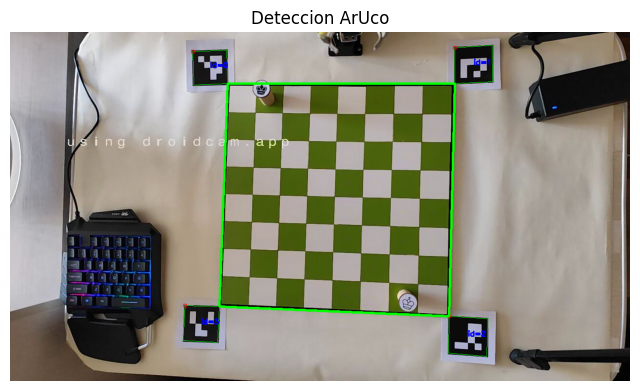

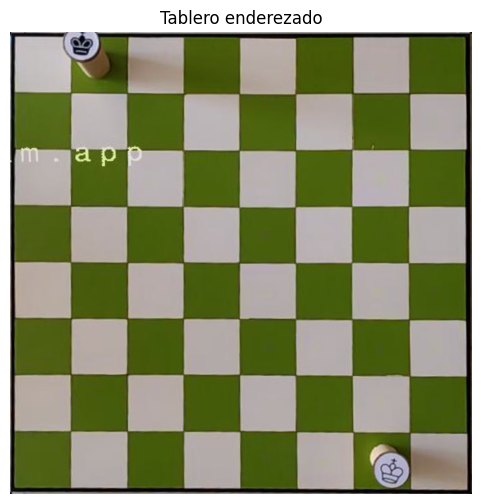

In [6]:
def capturar_tablero(source=None, max_frames=120, mostrar_cada=10):
    """
    Busca automaticamente un frame donde aparezcan los 4 ArUco.
    No usa cv2.imshow: muestra avances dentro del notebook cada cierto numero de frames.
    """
    if source is None:
        source = CAMERA_SOURCE

    cap = abrir_camara(source)
    tablero_capturado = None
    frame_capturado = None
    debug_capturado = None
    ultimo_frame = None
    ultimo_error = "Aun no se procesa ningun frame."

    print(f"Buscando tablero con 4 ArUco en fuente: {source}")

    try:
        for frame_idx in range(1, max_frames + 1):
            ok, frame = cap.read()
            if not ok or frame is None:
                ultimo_error = "No se pudo leer frame de la camara."
                time.sleep(0.05)
                continue

            ultimo_frame = frame.copy()

            try:
                tablero_actual, debug_actual, corners_tablero, ids = detectar_y_enderezar_tablero(frame)
                tablero_capturado = tablero_actual.copy()
                frame_capturado = frame.copy()
                debug_capturado = debug_actual.copy()
                print(f"Tablero detectado en frame {frame_idx}. ArUco detectados: {len(ids)}")
                break
            except Exception as exc:
                ultimo_error = str(exc)

            if mostrar_cada and frame_idx % mostrar_cada == 0:
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, ultimo_error[:80], (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 0, 255), 2)
                clear_output(wait=True)
                print(f"Frame {frame_idx}/{max_frames}. {ultimo_error}")
                mostrar_frame_notebook(frame_marcado, titulo="Buscando ArUco")

            time.sleep(0.03)
    finally:
        cap.release()

    if tablero_capturado is None:
        print("No se detecto el tablero dentro del limite de frames.")
        if ultimo_frame is not None:
            mostrar_frame_notebook(ultimo_frame, titulo="Ultimo frame capturado")
        return None, None, None

    timestamp = time.strftime("%Y%m%d_%H%M%S")
    frame_path = OUTPUT_DIR / f"captura_original_{timestamp}.jpg"
    debug_path = OUTPUT_DIR / f"captura_debug_aruco_{timestamp}.jpg"
    tablero_path = OUTPUT_DIR / f"tablero_enderezado_{timestamp}.jpg"

    cv2.imwrite(str(frame_path), frame_capturado)
    cv2.imwrite(str(debug_path), debug_capturado)
    cv2.imwrite(str(tablero_path), tablero_capturado)

    print("Original:", frame_path)
    print("Debug ArUco:", debug_path)
    print("Tablero enderezado:", tablero_path)

    mostrar_frame_notebook(debug_capturado, titulo="Deteccion ArUco")
    mostrar_frame_notebook(tablero_capturado, titulo="Tablero enderezado", figsize=(6, 6))

    return frame_capturado, tablero_capturado, tablero_path


# Ejecuta esta linea para capturar automaticamente cuando detecte 4 ArUco:
frame, tablero_recto, tablero_path = capturar_tablero(max_frames=240)


## 8. Mostrar tablero enderezado con grid

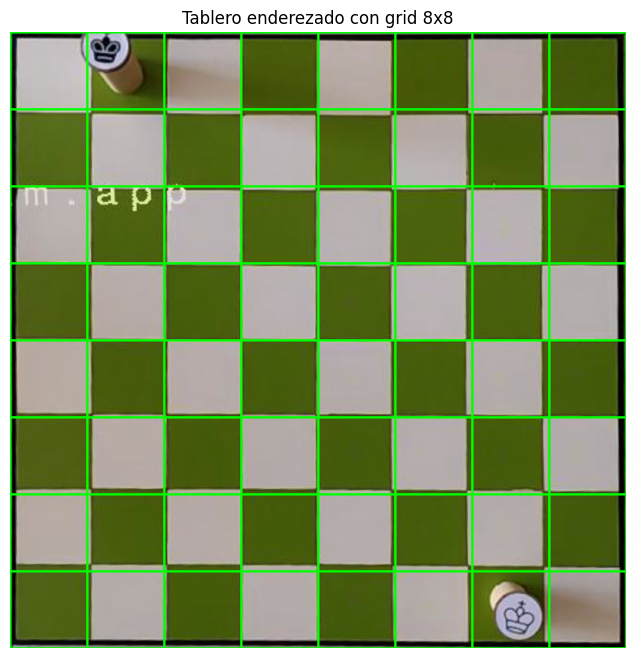

In [7]:
# Ejecuta despues de capturar el tablero.
# Si reiniciaste el kernel, puedes cargar manualmente una imagen guardada en Dataset/prueba_camara.

def mostrar_tablero_enderezado(tablero_bgr):
    if tablero_bgr is None:
        raise ValueError("Primero captura un tablero.")

    grid_img = dibujar_grid(tablero_bgr)

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB))
    plt.title("Tablero enderezado con grid 8x8")
    plt.axis("off")
    plt.show()


mostrar_tablero_enderezado(tablero_recto)


## 9. Segmentar en 64 casillas

Guarda cada casilla como `a8.jpg`, `b8.jpg`, ..., `h1.jpg`.

In [348]:
def nombre_casilla_ajedrez(fila, col):
    columnas = ["a", "b", "c", "d", "e", "f", "g", "h"]
    filas = ["8", "7", "6", "5", "4", "3", "2", "1"]
    return columnas[col] + filas[fila]


def segmentar_casillas_con_notacion(tablero_bgr, output_dir=CASILLAS_DIR, n=8, margin=CELL_MARGIN):
    if tablero_bgr is None:
        raise ValueError("Primero captura o carga un tablero enderezado.")

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n
    mx = int(cell_w * margin)
    my = int(cell_h * margin)

    casillas = []

    for fila in range(n):
        for col in range(n):
            y1 = fila * cell_h
            y2 = (fila + 1) * cell_h
            x1 = col * cell_w
            x2 = (col + 1) * cell_w

            casilla = tablero_bgr[y1 + my:y2 - my, x1 + mx:x2 - mx]
            nombre = nombre_casilla_ajedrez(fila, col)
            ruta = output_dir / f"{nombre}.jpg"
            cv2.imwrite(str(ruta), casilla)

            casillas.append({
                "casilla": nombre,
                "fila": fila,
                "columna": col,
                "imagen": casilla,
                "ruta": ruta,
            })

    print(f"Casillas guardadas: {len(casillas)}")
    print("Carpeta:", output_dir)
    return casillas


casillas = segmentar_casillas_con_notacion(tablero_recto)


Casillas guardadas: 64
Carpeta: c:\Users\User\Desktop\Brazo Robotico\Dataset\prueba_camara\casillas_ajedrez


## 9B. Guardar casillas para dataset sin sobrescribir

Esta celda guarda cada casilla con un nombre unico por captura. Asi puedes repetir muchas segmentaciones sin que `a8.jpg`, `b8.jpg`, etc. se reemplacen.

Modos utiles:
- `modo='por_casilla'`: guarda en carpetas `a8`, `b8`, etc. Sirve para revisar segmentacion por posicion.
- `modo='plano'`: guarda todo en una sola carpeta con nombre unico.
- `modo='por_clase'`: guarda en carpetas de clases como `peon_blanco`, `vacio`, etc., usando un diccionario de etiquetas que tu llenas para esa posicion del tablero.


In [349]:
from datetime import datetime
import csv

DATASET_SEGMENTADO_DIR = ROOT / "Dataset" / "casillas_dataset_generado"
DATASET_SEGMENTADO_DIR.mkdir(parents=True, exist_ok=True)

CLASES_PIEZAS = [
    "vacio",
    "peon_blanco", "caballo_blanco", "alfil_blanco", "torre_blanco", "reina_blanco", "rey_blanco",
    "peon_negro", "caballo_negro", "alfil_negro", "torre_negro", "reina_negro", "rey_negro",
]


def crear_id_captura(prefix="cap"):
    return f"{prefix}_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')[:-3]}"


def siguiente_ruta_disponible(carpeta, nombre_base, extension=".jpg"):
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)

    ruta = carpeta / f"{nombre_base}{extension}"
    if not ruta.exists():
        return ruta

    i = 1
    while True:
        ruta = carpeta / f"{nombre_base}_{i:03d}{extension}"
        if not ruta.exists():
            return ruta
        i += 1


def guardar_casillas_dataset(casillas, output_dir=DATASET_SEGMENTADO_DIR, modo="por_casilla", etiquetas=None, split=None, captura_id=None):
    """
    Guarda casillas sin sobrescribir archivos anteriores.

    Parametros:
    - casillas: lista devuelta por segmentar_casillas_con_notacion.
    - output_dir: carpeta destino.
    - modo:
        'por_casilla' -> output_dir/a8/a8_cap_....jpg
        'plano' -> output_dir/a8_cap_....jpg
        'por_clase' -> output_dir/train/peon_blanco/a8_cap_....jpg, si split='train'.
    - etiquetas: dict opcional {'a8': 'torre_negro', 'b8': 'caballo_negro', ...}. Solo necesario para modo='por_clase'.
    - split: 'train' o 'Val' si quieres guardar directo con estructura ImageFolder.
    - captura_id: id unico de captura. Si no se pasa, se genera uno automaticamente.
    """
    if not casillas:
        raise ValueError("No hay casillas para guardar.")

    output_dir = Path(output_dir)
    captura_id = captura_id or crear_id_captura()
    manifest_rows = []

    for item in casillas:
        nombre_casilla = item["casilla"]
        imagen = item["imagen"]

        if modo == "por_clase":
            if etiquetas is None or nombre_casilla not in etiquetas:
                raise ValueError(f"Falta etiqueta para la casilla {nombre_casilla}.")
            etiqueta = etiquetas[nombre_casilla]
            if etiqueta not in CLASES_PIEZAS:
                raise ValueError(f"Etiqueta no valida para {nombre_casilla}: {etiqueta}")
            carpeta = output_dir / split / etiqueta if split else output_dir / etiqueta
        elif modo == "por_casilla":
            etiqueta = nombre_casilla
            carpeta = output_dir / nombre_casilla
        elif modo == "plano":
            etiqueta = "sin_etiqueta"
            carpeta = output_dir
        else:
            raise ValueError("modo debe ser 'por_casilla', 'plano' o 'por_clase'.")

        nombre_base = f"{nombre_casilla}_{captura_id}"
        ruta = siguiente_ruta_disponible(carpeta, nombre_base, extension=".jpg")
        cv2.imwrite(str(ruta), imagen)

        manifest_rows.append({
            "captura_id": captura_id,
            "casilla": nombre_casilla,
            "etiqueta": etiqueta,
            "split": split or "",
            "ruta": str(ruta),
        })

    manifest_path = output_dir / "manifest_casillas.csv"
    existe = manifest_path.exists()
    with open(manifest_path, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["captura_id", "casilla", "etiqueta", "split", "ruta"])
        if not existe:
            writer.writeheader()
        writer.writerows(manifest_rows)

    print(f"Casillas guardadas sin sobrescribir: {len(manifest_rows)}")
    print("captura_id:", captura_id)
    print("Destino:", output_dir)
    print("Manifest:", manifest_path)
    return manifest_rows


# USO RAPIDO 1: guardar todas las casillas por posicion, sin reemplazar.
#filas = guardar_casillas_dataset(casillas, modo="por_casilla")

# USO RAPIDO 2: guardar en una carpeta plana con nombre unico.
filas = guardar_casillas_dataset(casillas, modo="plano")


Casillas guardadas sin sobrescribir: 64
captura_id: cap_20260602_155343_056
Destino: c:\Users\User\Desktop\Brazo Robotico\Dataset\casillas_dataset_generado
Manifest: c:\Users\User\Desktop\Brazo Robotico\Dataset\casillas_dataset_generado\manifest_casillas.csv


## 9C. Ejemplo para guardar directo como dataset por clase

Si sabes que posicion tiene cada pieza en el tablero fotografiado, llena el diccionario `etiquetas_tablero`. Esto guarda las casillas en estructura compatible con `ImageFolder`: `Dataset/EntrenamientoNuevo/train/clase/imagen.jpg`.


In [ ]:
# Cambia esta carpeta si quieres guardar directamente dentro de Dataset/Entrenamiento/train o Val.
DATASET_CLASIFICADO_DIR = ROOT / "Dataset" / "EntrenamientoNuevo"

# Ejemplo: posicion inicial de ajedrez vista desde blancas abajo.
# Edita este diccionario segun lo que haya realmente en tu tablero al momento de capturar.
etiquetas_tablero_inicial = {
    "a8": "torre_negro", "b8": "caballo_negro", "c8": "alfil_negro", "d8": "reina_negro", "e8": "rey_negro", "f8": "alfil_negro", "g8": "caballo_negro", "h8": "torre_negro",
    "a7": "peon_negro", "b7": "peon_negro", "c7": "peon_negro", "d7": "peon_negro", "e7": "peon_negro", "f7": "peon_negro", "g7": "peon_negro", "h7": "peon_negro",
    "a6": "vacio", "b6": "vacio", "c6": "vacio", "d6": "vacio", "e6": "vacio", "f6": "vacio", "g6": "vacio", "h6": "vacio",
    "a5": "vacio", "b5": "vacio", "c5": "vacio", "d5": "vacio", "e5": "vacio", "f5": "vacio", "g5": "vacio", "h5": "vacio",
    "a4": "vacio", "b4": "vacio", "c4": "vacio", "d4": "vacio", "e4": "vacio", "f4": "vacio", "g4": "vacio", "h4": "vacio",
    "a3": "vacio", "b3": "vacio", "c3": "vacio", "d3": "vacio", "e3": "vacio", "f3": "vacio", "g3": "vacio", "h3": "vacio",
    "a2": "peon_blanco", "b2": "peon_blanco", "c2": "peon_blanco", "d2": "peon_blanco", "e2": "peon_blanco", "f2": "peon_blanco", "g2": "peon_blanco", "h2": "peon_blanco",
    "a1": "torre_blanco", "b1": "caballo_blanco", "c1": "alfil_blanco", "d1": "reina_blanco", "e1": "rey_blanco", "f1": "alfil_blanco", "g1": "caballo_blanco", "h1": "torre_blanco",
}

# Para guardar como entrenamiento:
# filas = guardar_casillas_dataset(
#     casillas,
#     output_dir=DATASET_CLASIFICADO_DIR,
#     modo="por_clase",
#     etiquetas=etiquetas_tablero_inicial,
#     split="train",
# )

# Para guardar como validacion:
# filas = guardar_casillas_dataset(
#     casillas,
#     output_dir=DATASET_CLASIFICADO_DIR,
#     modo="por_clase",
#     etiquetas=etiquetas_tablero_inicial,
#     split="Val",
# )


## 10. Visualizar las 64 casillas segmentadas

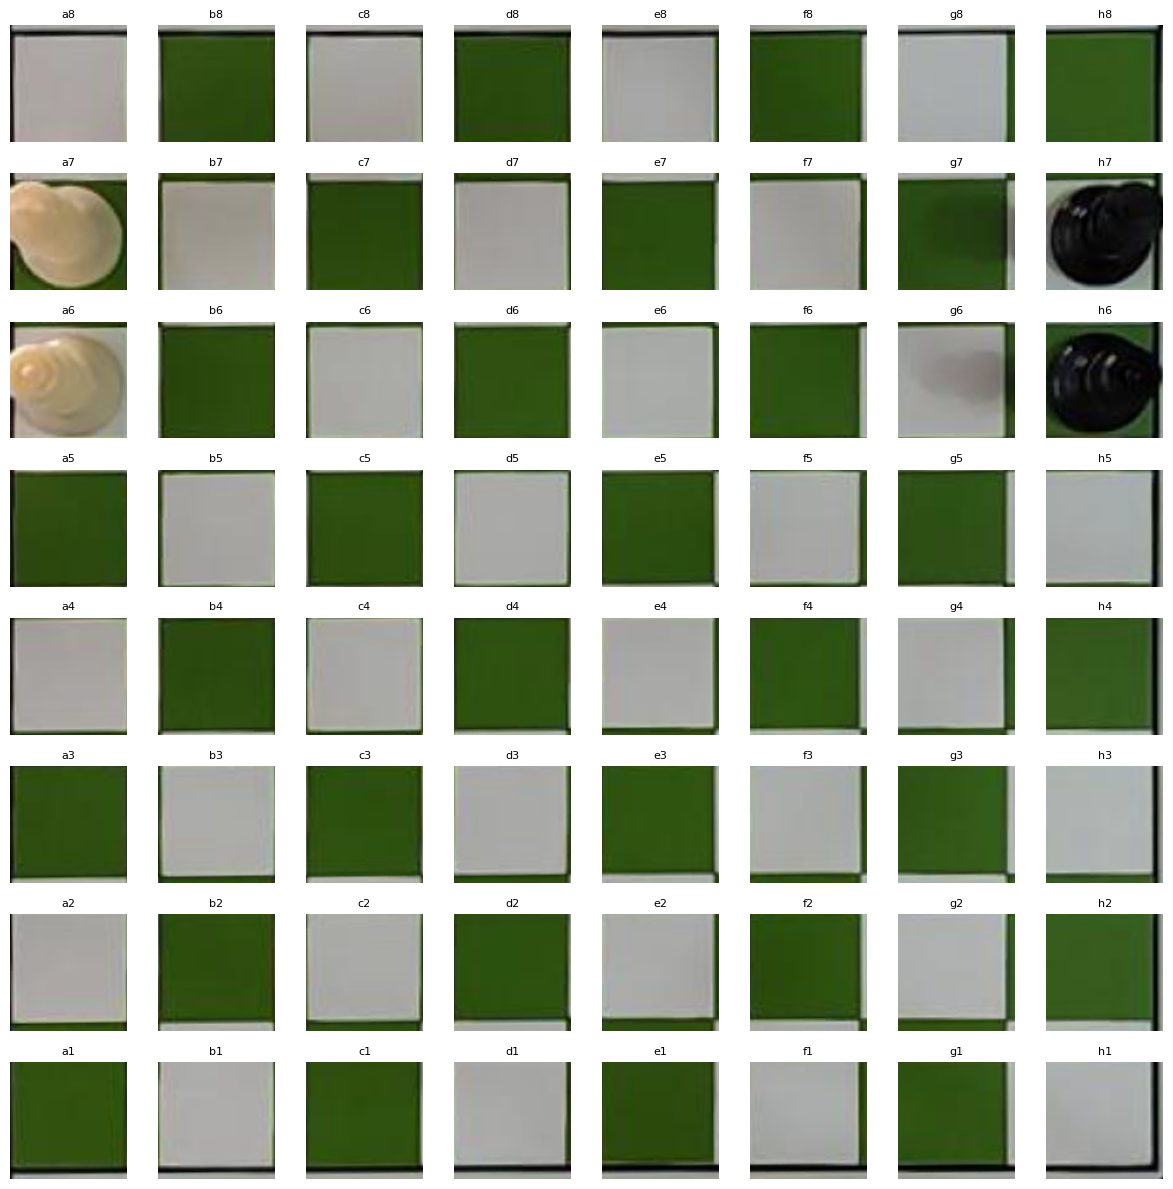

In [321]:
def mostrar_casillas(casillas):
    if not casillas:
        raise ValueError("No hay casillas para mostrar.")

    fig, axes = plt.subplots(8, 8, figsize=(12, 12))

    for item in casillas:
        fila = item["fila"]
        col = item["columna"]
        nombre = item["casilla"]
        casilla_rgb = cv2.cvtColor(item["imagen"], cv2.COLOR_BGR2RGB)

        axes[fila, col].imshow(casilla_rgb)
        axes[fila, col].set_title(nombre, fontsize=8)
        axes[fila, col].axis("off")

    plt.tight_layout()
    plt.show()


mostrar_casillas(casillas)


## 11. Flujo completo de prueba

Ejecuta esta celda cuando ya tengas `CAMERA_INDEX` correcto. Hace todo el flujo: captura, endereza, muestra grid, segmenta y muestra casillas.

In [ ]:
def prueba_completa_camara(source=None):
    if source is None:
        source = CAMERA_SOURCE

    frame, tablero_recto, tablero_path = capturar_tablero(source, max_frames=120)

    if tablero_recto is None:
        print("No se capturo tablero. Revisa CAMERA_SOURCE, iluminacion, enfoque y tipo de ArUco.")
        return None

    mostrar_tablero_enderezado(tablero_recto)
    casillas = segmentar_casillas_con_notacion(tablero_recto)
    mostrar_casillas(casillas)

    return {
        "frame": frame,
        "tablero_recto": tablero_recto,
        "tablero_path": tablero_path,
        "casillas": casillas,
    }


# resultado = prueba_completa_camara()


## 12. Cargar una captura guardada y segmentarla de nuevo

Util si ya capturaste una imagen y solo quieres repetir la segmentacion sin abrir DroidCam.

In [ ]:
def cargar_tablero_guardado(path):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(path)
    return img


# Ejemplo:
# ultimo = sorted(OUTPUT_DIR.glob("tablero_enderezado_*.jpg"))[-1]
# tablero_recto = cargar_tablero_guardado(ultimo)
# mostrar_tablero_enderezado(tablero_recto)
# casillas = segmentar_casillas_con_notacion(tablero_recto)
# mostrar_casillas(casillas)
